In [10]:
#Library

%matplotlib inline
    
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import astropy
import pandas as pd

from IPython.display import Image,HTML,IFrame
from astropy.io import fits as pyfits
import urllib.request

#import gt_apps as gt

from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord, search_around_sky
from astropy.coordinates import Angle
pd.set_option('display.max_rows', None)

import sys
import os
os.environ['LVDBDIR'] = '../local_volume_database'
sys.path.append('../local_volume_database')

import local_volume_database as lvdb

# List all *.csv files

In [12]:
## Input for latex table, load locally

#Read through *.csv file. These are Dwarf Galaxies.
comb_all_local = Table.read('../local_volume_database/data/dwarf_all.csv')
#comb_local_field = table.Table.read('../local_volume_database/data/dwarf_local_field.csv')
#comb_local_field_distant = table.Table.read('../local_volume_database/data/dwarf_local_field_distant.csv')

#Read through *.csv file. These are Globular Clusters.
#comb_gc_ambiguous = table.Table.read('../local_volume_database/data/gc_ambiguous.csv')
#comb_gc_dwarf_hosted = table.Table.read('../local_volume_database/data/gc_dwarf_hosted.csv')
#comb_gc_harris = table.Table.read('../local_volume_database/data/gc_harris.csv')
#comb_mw_new = table.Table.read('../local_volume_database/data/gc_mw_new.csv')
#comb_other = table.Table.read('../local_volume_database/data/gc_other.csv')

### Papers

When going through the sources that were used in papers, I found that I have filtered out some of the sources they use for their respective analysis. Also, some of the sources that I have not filtered out were omitted sources in specific papers (but not ommited in others). 

1. "A Global Analysis of Dark Matter Signals from 27 Dwarf SpheroidalGalaxies using 11 Years of Fermi-LAT Observations"

- "Removing WILLMAN 1...we consider to 27: AQUARIUS II, BOÖTES I, CANES VENATICI I, CANES VENATICI II, CARINA, CARINA II, COMA BERENICES, DRACO, DRACO II, FORNAX, GRUS I, HERCULES, HOROLOGIUM I, LEO I, LEO II, LEO IV, LEO V, PEGASUS III, PISCES II, RETICULUM II, SCULPTOR, SEGUE 1, SEXTANS, TUCANA II, URSA MAJOR I, URSA MAJOR II, and URSA MINOR.

- Studied are all Milky Way satellites, except Ret II, which needed to be treated differently than the other sources due to "Selecting significantly more data for this comparison was not possible, since PASS 7 was discontinued after week 368 and we want to use the same observation time for both PASS 7 and PASS 8 to enable a meaningful comparison."

- Willman I was removed due to strong evidence for tidal disruption and/or nonequilibrium kinematics, which would inflate velocity dispersions (and overestimate annihilation factor, J).


2. "Searching for dark matter annihilating into light long-lived mediators from stars inside dwarf spheroidal galaxies"

- Sources: Draco II, Segue I, Sagittarius, Hydrus I, Reticulum II, Ursa Major II, Carina II, Bootes II, Willman I, Coma Berenices.

3. "Scaling Relations for Dark Matter Annihilation and Decay Profiles in Dwarf Spheroidal Galaxies"

- Compilation of J/D Factors for MW, M31, and Local Field dSphs.

4. "New dark matter analysis of milky way dwarf satellite galaxies with MADHATV2"

- 54 dSphs, likelihood stack with J-factors?

5."Leo I: the classical dwarf spheroidal galaxy with the highest dark-matter density"

- Leo I

6. "Prospects for dark matter observations in dwarf spheroidal galaxies with the Cherenkov Telescope Array Observatory"

- "From an initial sample of 64 dSphs, eight promising targets are identified – Draco I,
Coma Berenices, Ursa Major II, Ursa Minor and Willman 1 in the North, Reticulum II, Sculptor and Sagittarius II in the South- for which different DM density models yield consistent expectations, leading to robust predictions."

- Narrowed down the best canidates for DM signals, using the following selection criterion: i) Distance selection of $d \leq 100 $kpc (remove dSphs for which we expect low values of $J_{ann}$, leaves us with 35 candidates), ii) Investigate quality and availability of spectro-photometric data (discard those with missing and unreliable data, 14 sources remaining), and iii) Select highest values of $J_{ann}$ (8 targets left).


Next list is me trying to also include the sources they used, such that a reference can be made to those specific papers. I don't believe that the sources that were omitted in certain papers would be neccesarily a problem for us, due to their analysis being heavily dependent on velocity dispersions not being calculated correctly (implying its overestimations in J-factor). Since we are not directly using the J-factor, would it make sense to omit certain DGs based on this reasoning?

### Distance Limiting
Apply a distance selection. CTAO paper does this to weed out dSphs (both cls and ufd) that will naturally have very low annihilation rates due to being quite far away. This is based on Equation 4 in their paper. I assume that the higher the annihilation rates, the more that specific DG will shine in the high energy band (gamma); if the DGs are too far away, then the less they will shine (?).

# For dwarf_all.csv file
This file should list all the dwarf galaxies, along with their host.

## All Dwarf Galaxies in LVDB

In [13]:
#Limit Distance Modulus to 1 Mpc, \mu = 5log_10(d)-5, d in pc, \mu in magnitude, make this 25

test_system = comb_all_local[comb_all_local['distance_modulus'] <= 25.0]

print(len(test_system))
#print(test_system)

124


In [14]:
#Find all dwarf galaxies with declination above 20 degrees above/below galactic plane

#Get the RA and Dec of catalog
coords = SkyCoord(ra=test_system['ra'] * u.degree, dec=test_system['dec'] * u.degree, frame='icrs')

#Transform into Galactic Coordinates
galactic_coords = coords.galactic

#Put in the galactic coordinates to work with
test_system['gal_l'] = galactic_coords.l.deg
test_system['gal_b']  = galactic_coords.b.deg


test_system = test_system[abs(test_system['gal_b']) >= 20.0]
print(len(test_system))
#print(test_system)

101


In [15]:
# Convert the column slice to a pandas dataframe for standard viewing
test_system['key', 'name', 'gal_l', 'gal_b', 'host'].to_pandas()

#.sort_values(by=['ra', 'dec'], ascending=False)

,key,name,gal_l,gal_b,host
0,aquarius_2,Aquarius II,55.108244,-53.008500,mw
1,aquarius_3,Aquarius III,87.916690,-62.029717,mw
2,aquarius_4,Aquarius IV,56.693233,-42.624510,mw
3,bootes_1,Bootes I,358.101946,69.636576,mw
4,bootes_2,Bootes II,353.731375,68.864902,mw
5,bootes_3,Bootes III,34.527402,75.101191,mw
6,bootes_4,Bootes IV,70.682250,53.305004,mw
7,bootes_5,Bootes V,55.667950,70.917681,mw
8,canes_venatici_1,Canes Venatici I,74.304283,79.828759,mw
9,canes_venatici_2,Canes Venatici II,113.574376,82.701205,mw


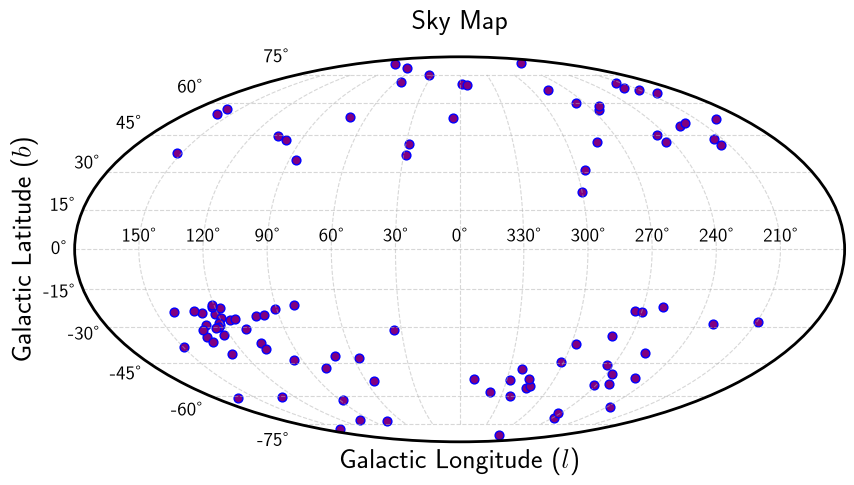

In [16]:
#I want a Sky Map, and I want it now!

#Convert to radians
l_rad = Angle(test_system['gal_l'] * u.degree).wrap_at(180 * u.degree).radian
b_rad = np.radians(test_system['gal_b'])

#Make Plot
plt.figure(figsize=(10,5))
ax = plt.subplot(111, projection= 'mollweide')

#Plot All 36 dwarf galaxies, negative l_rad to match astronomical convention
ax.scatter(-l_rad, b_rad, s=40, c='purple' ,edgecolor='blue')

#Format the grid and labels
ax.grid(True, linestyle='--', alpha=0.5)

#Convert x-axis tick labels back to standard degrees for readability
x_ticks = np.radians([-150, -120, -90, -60, -30, 0, 30, 60, 90, 120, 150])
x_labels = ['150°', '120°', '90°', '60°', '30°', '0°', '330°', '300°', '270°', '240°', '210°']
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels)

#Set axis titles
ax.set_title("Sky Map", pad=20, fontsize=20, fontweight='bold')
ax.set_xlabel(r"Galactic Longitude ($l$)")
ax.set_ylabel(r"Galactic Latitude ($b$)")

#Again, I stole this from Google Gemini because I like the names
'''galaxy_names = test_system['name']
colors = plt.cm.hsv(np.linspace(0, 1, len(galaxy_names)))
for name, x, y in zip(galaxy_names, -l_rad, b_rad):
    ax.annotate(
        name, 
        xy=(x, y),                # Point to annotate
        xytext=(5, 5),            # Offset text slightly by 5 points right and 5 points up
        textcoords='offset points', # Interpret xytext as offset pixel points
        fontsize=8,               # Small clean font size for 36 points
        fontweight='medium',
        alpha=0.85,               # Slightly soft text color so the grid remains legible
        zorder=4
    )'''

plt.show()

<Figure size 640x480 with 0 Axes>

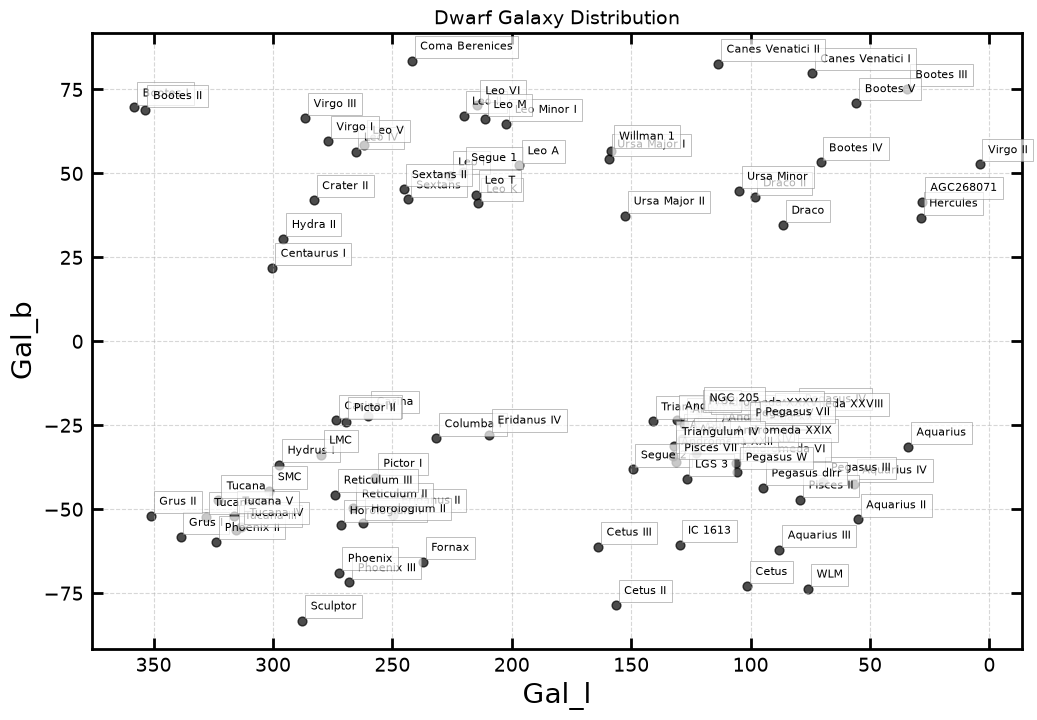

In [17]:
#I want to be able to get the data for multiple sources at one time. 
catalog_plot = test_system['key', 'name', 'gal_l', 'gal_b', 'host'].to_pandas()

#I Googled this to make sure I don't spend that much time plotting lol
plt.clf()
plt.rcParams['text.usetex'] = False
plt.figure(figsize=(12, 8))
plt.scatter(catalog_plot['gal_l'], catalog_plot['gal_b'], alpha=0.7, c='black', s=40)

# Matplotlib-only method: shifts text box automatically using padding points
for idx, row in catalog_plot.iterrows():
    plt.annotate(
        str(row['name']),
        xy=(row['gal_l'], row['gal_b']),
        xytext=(6, 6),               # Offset text by 6 points up and right
        textcoords="offset points", 
        fontsize=8,
        va='bottom', 
        ha='left',
        bbox=dict(boxstyle= None, fc='white', alpha=0.7, ec='gray', lw=0.5)
    )

plt.gca().invert_xaxis()
plt.xlabel('Gal_l')
plt.ylabel('Gal_b')
plt.title('Dwarf Galaxy Distribution')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Subtracting Sources Near 4FGL Sources

In [18]:
#Getting 4FGL sources, I believe this v41 is the most recent one
catalog_4fgl = Table.read("../conda/fermipy/fermipy/data/catalogs/gll_psc_v41.fit")

#Get this into a SkyCoord object, asap!
c4fgl_coords = SkyCoord(l=catalog_4fgl["GLON"], b=catalog_4fgl["GLAT"], frame='galactic')

In [19]:
#Make this into SkyCoord object as well
dg_coords = SkyCoord(l=catalog_plot['gal_l'].values * u.deg, b=catalog_plot['gal_b'].values * u.deg, frame='galactic')

In [83]:
#Search Around the Sky, a neoclassical song in the making

#For sources in my catalog, I want to search around a radius of 1 degree to see if there are any 4FGL sources
idxc, idxcatalog, d2d, d3d = dg_coords.search_around_sky(c4fgl_coords, 1*u.deg) 

#idxc = indexing 4FGL catalog
#idxcatalog = indexing il mio catalog
#d2d = 2D distances
#d3d= 3D distances

#Accept all 2D distances less than 1 degree, but shouldn't the last line do that? Why Astropy, why?
#np.all(d2d < 1*u.deg)
print(len(idxc), len(idxcatalog))
print(idxc, idxcatalog) 

48 48
[  20  134  136  175  184  186  186  191  199  199  203  203  232  232
  257  261  263  266  319  383  395  642  713  764  824  869  952 1002
 1264 1281 1336 1356 1784 2638 2703 2837 2875 2906 3126 3319 3332 3336
 4482 6714 6908 6929 6961 6968] [100  80  90  66  83  82  83  64  82  83  68  69  68  70  51  51  73  46
  51  86  87  29  22  26  27  27  44  45  21  21  36  36  11  49  50  63
  35  94  17  62  16  62  88  24  53  53  85  43]


In [68]:
#What will be removed
friends_forever = catalog_plot.iloc[idxcatalog]
print('DGs within 1 degree of a 4FGL source:', len(friends_forever))
friends_forever

DGs within 1 degree of a 4FGL source: 48


,key,name,gal_l,gal_b,host
100,wlm,WLM,75.863686,-73.624352,NaN
80,andromeda_35,Andromeda XXXV,117.802943,-22.516582,m_031
90,cetus_1,Cetus,101.454841,-72.854557,NaN
66,andromeda_03,Andromeda III,119.364173,-26.262529,m_031
83,ngc_0205,NGC 205,120.717803,-21.137794,m_031
82,m_032,M 32,121.149896,-21.976388,m_031
83,ngc_0205,NGC 205,120.717803,-21.137794,m_031
64,andromeda_01,Andromeda I,121.678858,-24.820193,m_031
82,m_032,M 32,121.149896,-21.976388,m_031
83,ngc_0205,NGC 205,120.717803,-21.137794,m_031


In [78]:
#Final Sources
catalog_final = catalog_plot.drop(friends_forever.index).reset_index(drop=True) #Drop BFFs, and know a life without 4FGL sources around you

print('Original catalog size:', len(catalog_plot))
print('Filtered catalog size:', len(catalog_final))
print('Number of dwarf galaxies removed:', len(catalog_plot) - len(catalog_final))

catalog_final

Original catalog size: 101
Filtered catalog size: 64
Number of dwarf galaxies removed: 37


,key,name,gal_l,gal_b,host
0,aquarius_2,Aquarius II,55.108244,-53.008500,mw
1,aquarius_3,Aquarius III,87.916690,-62.029717,mw
2,aquarius_4,Aquarius IV,56.693233,-42.624510,mw
3,bootes_1,Bootes I,358.101946,69.636576,mw
4,bootes_2,Bootes II,353.731375,68.864902,mw
5,bootes_3,Bootes III,34.527402,75.101191,mw
6,bootes_4,Bootes IV,70.682250,53.305004,mw
7,bootes_5,Bootes V,55.667950,70.917681,mw
8,canes_venatici_1,Canes Venatici I,74.304283,79.828759,mw
9,canes_venatici_2,Canes Venatici II,113.574376,82.701205,mw


### Notes

I've removed some pretty important sources. =0 Whoops. How do I remove sources that are around 4FGL sources, but not the actual source itself? What if I tranformed into galactic coords wrong? No, did not transform wrong.

In [82]:
test_system['key', 'name','ll','gal_l','bb', 'gal_b'].to_pandas()

,key,name,ll,gal_l,bb,gal_b
0,aquarius_2,Aquarius II,55.108244,55.108244,-53.008500,-53.008500
1,aquarius_3,Aquarius III,87.916690,87.916690,-62.029717,-62.029717
2,aquarius_4,Aquarius IV,56.693233,56.693233,-42.624510,-42.624510
3,bootes_1,Bootes I,358.101946,358.101946,69.636576,69.636576
4,bootes_2,Bootes II,353.731375,353.731375,68.864902,68.864902
5,bootes_3,Bootes III,34.527402,34.527402,75.101191,75.101191
6,bootes_4,Bootes IV,70.682250,70.682250,53.305004,53.305004
7,bootes_5,Bootes V,55.667950,55.667950,70.917681,70.917681
8,canes_venatici_1,Canes Venatici I,74.304283,74.304283,79.828759,79.828759
9,canes_venatici_2,Canes Venatici II,113.574376,113.574376,82.701205,82.701205
